# **Arena**

## **Section 1: Setting directory and preparing the dataset**

In [ ]:
%%capture
!pip install torchmetrics
!pip install pkbar
!pip install calflops
!pip install torchinfo
!pip install grad-cam

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Drive Directory**

In [ ]:
import os
import zipfile
import json
import pandas as pd
import numpy as np
import random as rd
import shutil
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torchvision
from torchvision.transforms import v2, InterpolationMode
import timm
import calflops
from functools import partial

In [ ]:
drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
dataset_name = 'MushroomB'
dataset_drive_dir = f'{drive_dir}/data/{dataset_name}'

modify_type = 'C3'
model_name_path = f'convnext_tiny_modify_{modify_type}_224_r1_v1' # เปลี่ยนเสมอ
model_name = 'ConvNeXt-Tiny' # เปลี่ยนเสมอ

sigle_model_title = f'{model_name} Modify-{modify_type} on {dataset_name} Dataset'
ensemble_model_title = f'{model_name} Modify-{modify_type} Ensemble on {dataset_name} Dataset'
model_dir = os.path.join(drive_dir, f'myModelWeights/{dataset_name}', f"{model_name_path}_{dataset_name}")
model_ensem_dir = f'{model_dir}/ensemble'
model_summary_dir = f'{model_dir}/summary'

os.makedirs(model_dir, exist_ok=True)
font_dir = f'{drive_dir}/assets/fonts'

os.chdir(f'{drive_dir}')
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


**Runtime Directory**

In [ ]:
import src.reproducibility as reproducibility
import src.utils as utils
import src.datasets as datasets
import src.train as train
import src.test as test
import src.visualization as visualization
import src.gradCam as gradCam
import models.models as models

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')
def callbacks_fn(n_fold, fold_dir):
    checkpoint_path = f'{fold_dir}/{model_name_path}_{dataset_name}_best_weight.pth'
    return [utils.ModelCheckpoint(save_path=checkpoint_path, monitor=train.train_config['monitor'], mode=train.train_config['monitor_mode'])]

In [ ]:
runtime_dir = '/content'
dataset_dir = f'{runtime_dir}/{dataset_name}'
os.makedirs(dataset_dir, exist_ok=True)

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on {device}.')
!python3 --version
!nvidia-smi

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Running on cuda.
Python 3.12.12
Wed Mar 18 04:51:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   42C    P8             13W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         | 

**Load data from G-Drive**

In [ ]:
with zipfile.ZipFile(f'{dataset_drive_dir}/{dataset_name}_SPLIT.zip', 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

remain_classes = set(os.listdir(f'{dataset_dir}/remain'))
test_classes = set(os.listdir(f'{dataset_dir}/test'))
unique_classes = remain_classes.union(test_classes)
NUM_CLASSES = len(unique_classes)
print(f'Number of classes: {NUM_CLASSES}')
print(f'Dataset has been extracted to {dataset_dir}')

Number of classes: 16
Dataset has been extracted to /content/MushroomB


## **Section 2: Define model architecture**

In [ ]:
model_fn = partial(
    models.build_modify_convnext,
    model_name=model_name,
    num_classes=NUM_CLASSES,
    device=device,
    target_stages=[0,1,2,3],
    freeze_backbone=False,
    modify_type=modify_type
)
model = model_fn()

criterion = nn.CrossEntropyLoss()
optimizer_fn = lambda m : optim.AdamW(m.parameters(), lr=train.train_config['base_lr'], weight_decay=train.train_config['weight_decay'])
scheduler_fn = partial(optim.lr_scheduler.CosineAnnealingLR, T_max=train.train_config['max_epochs'])

model_config = models.get_transform_config(model)
summary(model, (1,) + model_config['input_size'], device=device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Layer (type:depth-idx)                                  Output Shape              Param #
ConvNeXt                                                [1, 16]                   --
├─Sequential: 1-1                                       [1, 96, 56, 56]           --
│    └─Conv2d: 2-1                                      [1, 96, 56, 56]           4,704
│    └─LayerNorm2d: 2-2                                 [1, 96, 56, 56]           192
├─Sequential: 1-2                                       [1, 768, 7, 7]            --
│    └─ConvNeXtStage: 2-3                               [1, 96, 56, 56]           --
│    │    └─Identity: 3-1                               [1, 96, 56, 56]           --
│    │    └─Sequential: 3-2                             [1, 96, 56, 56]           252,048
│    └─ConvNeXtStage: 2-4                               [1, 192, 28, 28]          --
│    │    └─Sequential: 3-3                             [1, 192, 28, 28]          74,112
│    │    └─Sequential: 3-4                    

## **Section 3: Preparing the dataset**

**Configuration for training**

In [ ]:
img_size = model_config['img_size']
resize_size = int(img_size[0] / model_config['crop_pct'])
interp_mode = getattr(InterpolationMode, model_config['interpolation'].upper())
num_workers = min(4, os.cpu_count())

print(f'Image size: {img_size}')
print(f'Resize size: {resize_size}')
print(f'Interpolation mode: {interp_mode}')
print(f'Number of workers: {num_workers}')

reproducibility.global_seed(seed=train.train_config['seed'])
reproducibility.training_seed(seed=train.train_config['seed'])
g = reproducibility.get_generator(seed=train.train_config['seed'])

Image size: (224, 224)
Resize size: 256
Interpolation mode: InterpolationMode.BICUBIC
Number of workers: 4
Global Seed set to: 42
Training Seed set to: 42


In [ ]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(img_size, scale=(0.3, 1.0), interpolation=interp_mode),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandAugment(num_ops=2, magnitude=6, interpolation=interp_mode),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std']),
    v2.RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False)
])

transform = v2.Compose([
    v2.Resize(resize_size, interpolation=interp_mode, max_size=None, antialias=True),
    v2.CenterCrop(img_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std'])
])

dataloader_kwargs = {
    'batch_size': train.train_config['batch_size'],
    'num_workers': num_workers,
    'worker_init_fn': reproducibility.seed_worker,
    'generator': g,
    'pin_memory': True
}

datasets = datasets.Datasets(
    dataset_dir=dataset_dir,
    train_transform=train_transform,
    transform=transform,
    dataloader_kwargs=dataloader_kwargs,
)

datasets.print_summary()
test_loader = datasets.get_test_loader()

--------------------------------------------------
Dataset Summary
--------------------------------------------------
Class names       : ['Amanita_Caesarea-Edible', 'Amanita_Citrina-Edible', 'Amanita_Pantherina-NotEdible', 'Boletus_Regius-Edible', 'Clitocybe_Costata-Edible', 'Entoloma_Lividum-NotEdible', 'Gyromitra_Esculenta-NotEdible', 'Helvella_Crispa-Edible', 'Hydnum_Rufescens-NotEdible', 'Hygrophorus_Latitabundus-Edible', 'Morchella_Deliciosa-Edible', 'Omphalotus_Olearius-NotEdible', 'Phallus_Impudicus-NotEdible', 'Rubroboletus_Satanas-NotEdible', 'Russula_Cyanoxantha-Edible', 'Russula_Delica-NotEdible']
Class to Index    : {'Amanita_Caesarea-Edible': 0, 'Amanita_Citrina-Edible': 1, 'Amanita_Pantherina-NotEdible': 2, 'Boletus_Regius-Edible': 3, 'Clitocybe_Costata-Edible': 4, 'Entoloma_Lividum-NotEdible': 5, 'Gyromitra_Esculenta-NotEdible': 6, 'Helvella_Crispa-Edible': 7, 'Hydnum_Rufescens-NotEdible': 8, 'Hygrophorus_Latitabundus-Edible': 9, 'Morchella_Deliciosa-Edible': 10, 'Ompha

## **Section 4: Training the model**

In [ ]:
trainer = train.KFoldTrainer(
    n_splits=train.train_config['n_folds'],
    shuffle=True,
    random_state=train.train_config['seed'],
    model_name=model_name_path,
    dataset_name=dataset_name,
    base_dir=model_dir,
    first_metric=train.train_config['first_metric'],
    first_metric_mode=train.train_config['first_metric_mode'],
    secondary_metric=train.train_config['secondary_metric'],
    secondary_metric_mode=train.train_config['secondary_metric_mode'],
    device=device,
    criterion=criterion,
    n_classes=NUM_CLASSES,
    task=train.train_config['task'],
    average=train.train_config['average'],
    max_grad_norm=0.0
)

[Logs] Setup directories at '/content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB' successfully.


In [ ]:
fold_histories = trainer.fit_kfold(
    train_dataset=datasets.train_dataset,
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    model_fn=model_fn,
    optimizer_fn=optimizer_fn,
    epochs=train.train_config['max_epochs'],
    dataloader_kwargs=dataloader_kwargs,
    callbacks_fn=callbacks_fn,
    scheduler_fn=scheduler_fn
)

Starting Stratified 5-Fold Cross Validation

--------------------------------------------- FOLD 1/5 ---------------------------------------------
Epoch: 1/30
60/60 [==============================] - 27s 452ms/step - loss: 2.1885 - lr: 1.0000e-04 - accuracy: 0.4325 - f1: 0.3647 - precision: 0.5407 - recall: 0.3579
Epoch 1/30 | val_loss: 1.2095 - val_accuracy: 0.8396 - val_f1: 0.7928 - val_precision: 0.8896 - val_recall: 0.7897
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.8396, saving model to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/fold_1/convnext_tiny_modify_C3_224_r1_v1_MushroomB_best_weight.pth
Epoch: 2/30
60/60 [==============================] - 19s 310ms/step - loss: 0.7491 - lr: 9.9726e-05 - accuracy: 0.8859 - f1: 0.8664 - precision: 0.8847 - recall: 0.8577
Epoch 2/30 | val_loss: 0.3389 - val_accuracy: 0.9563 - val_f1: 0.9532 - val_precision: 0.9563 - val_recall: 0.9541
[Logs] Epoch: 2 val_accuracy improve

Epoch: 1/30
60/60 [==============================] - 19s 315ms/step - loss: 2.0932 - lr: 1.0000e-04 - accuracy: 0.4653 - f1: 0.3829 - precision: 0.5159 - recall: 0.3859
Epoch 1/30 | val_loss: 1.0948 - val_accuracy: 0.8521 - val_f1: 0.7902 - val_precision: 0.8752 - val_recall: 0.7928
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.8521, saving model to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/fold_4/convnext_tiny_modify_C3_224_r1_v1_MushroomB_best_weight.pth
Epoch: 2/30
60/60 [==============================] - 19s 320ms/step - loss: 0.6965 - lr: 9.9726e-05 - accuracy: 0.8937 - f1: 0.8757 - precision: 0.8995 - recall: 0.8675
Epoch 2/30 | val_loss: 0.2662 - val_accuracy: 0.9708 - val_f1: 0.9670 - val_precision: 0.9664 - val_recall: 0.9687
[Logs] Epoch: 2 val_accuracy improved from 0.8521 to 0.9708, saving model to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_Mushroo

## **Section 5: Individual model performance**

In [ ]:
y_true = test.get_true_label(test_loader, is_onehot=False)

### **Learning curve**

#### **Individual**

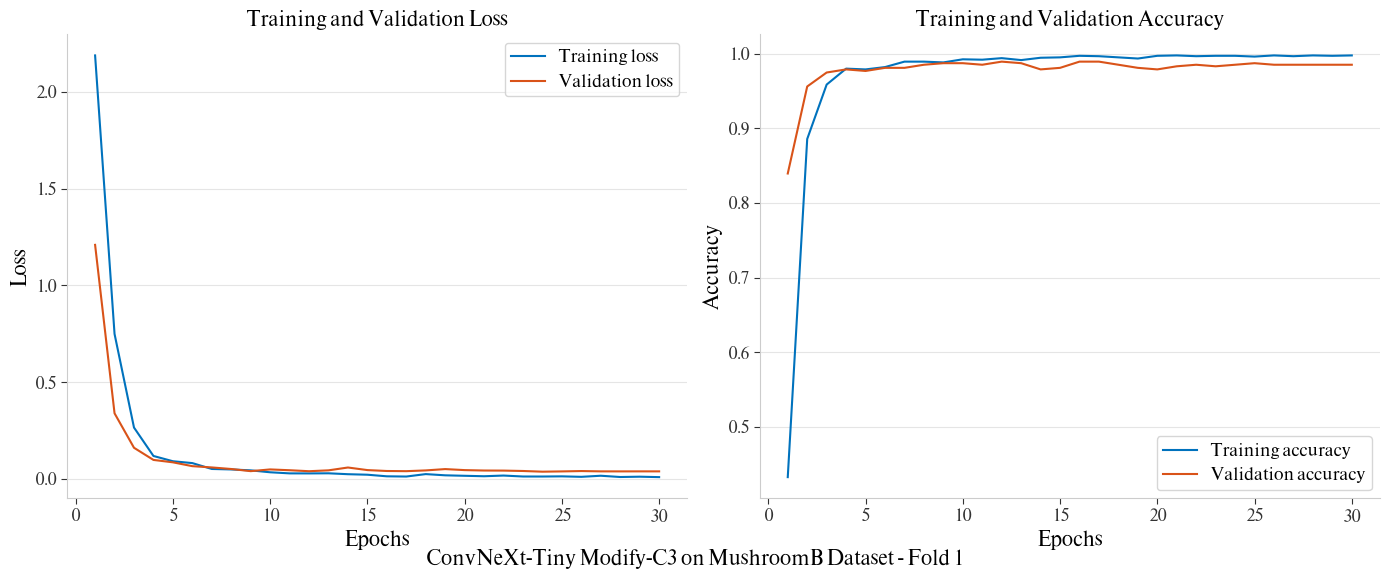

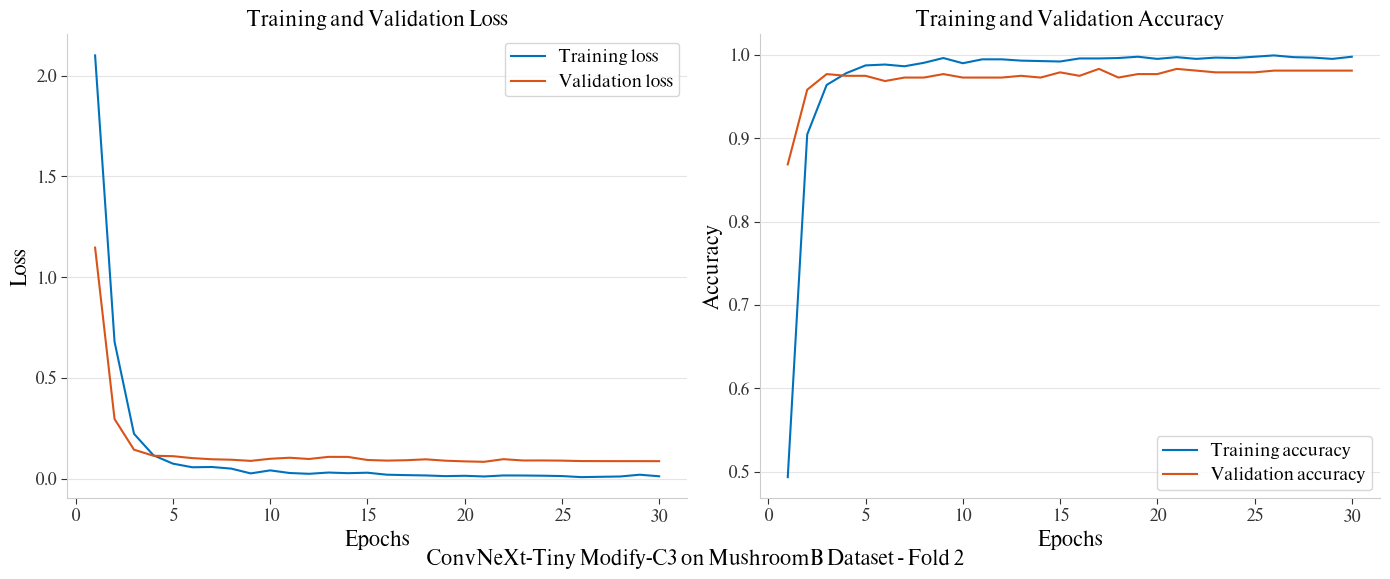

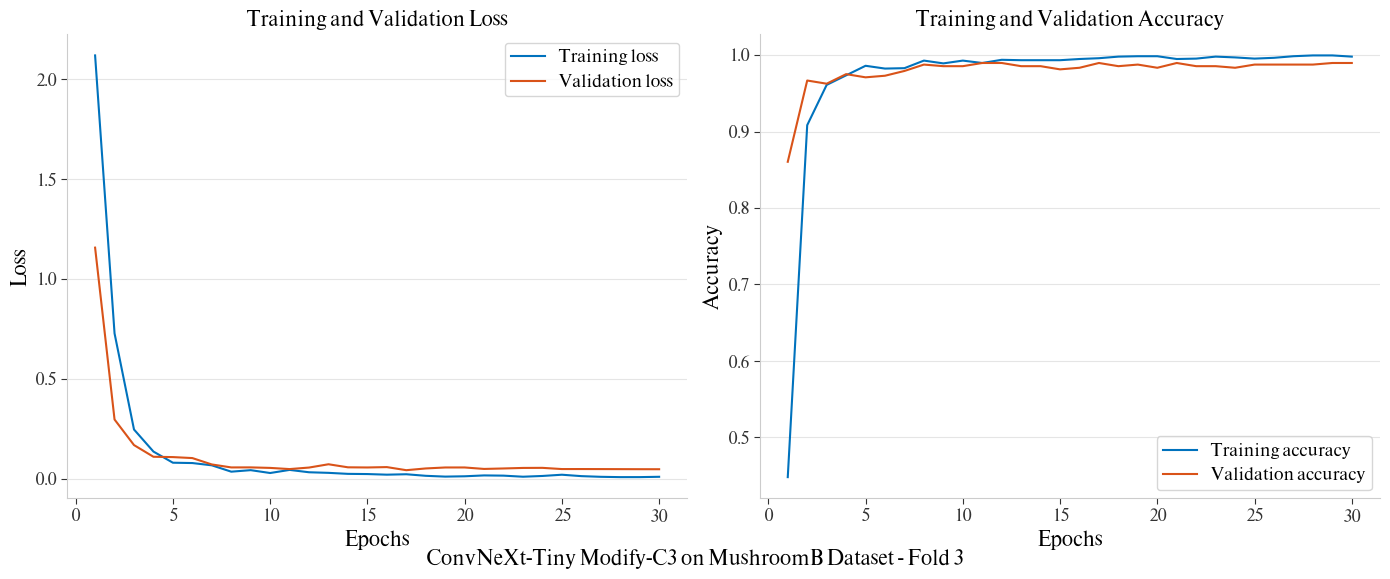

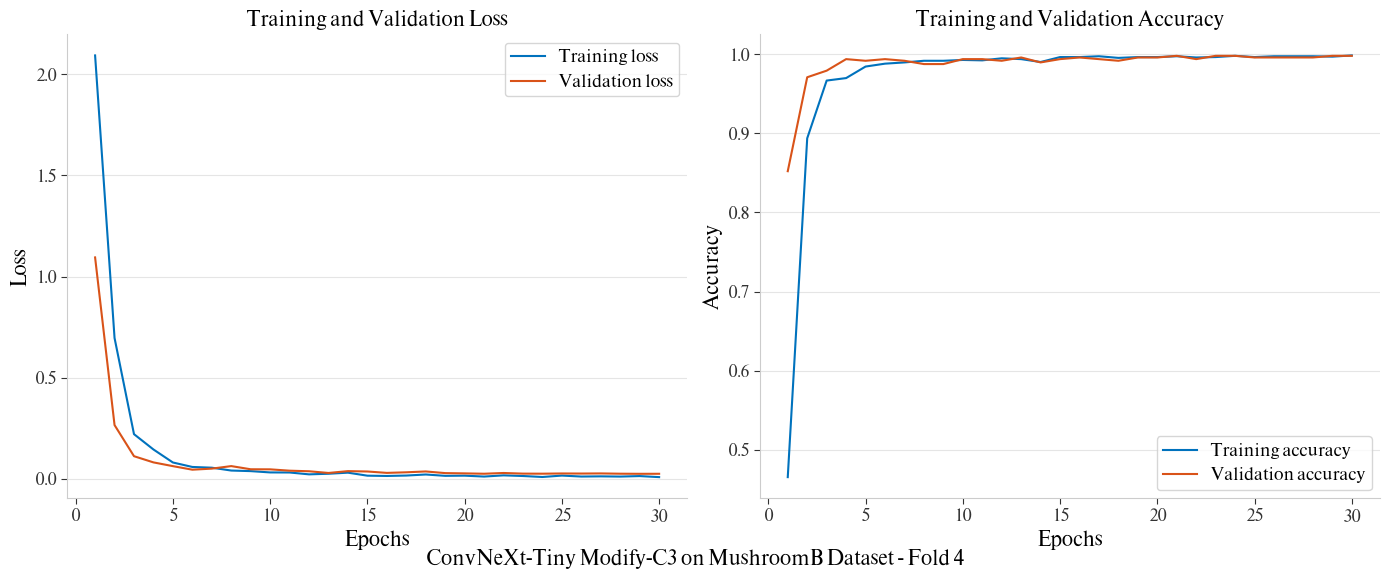

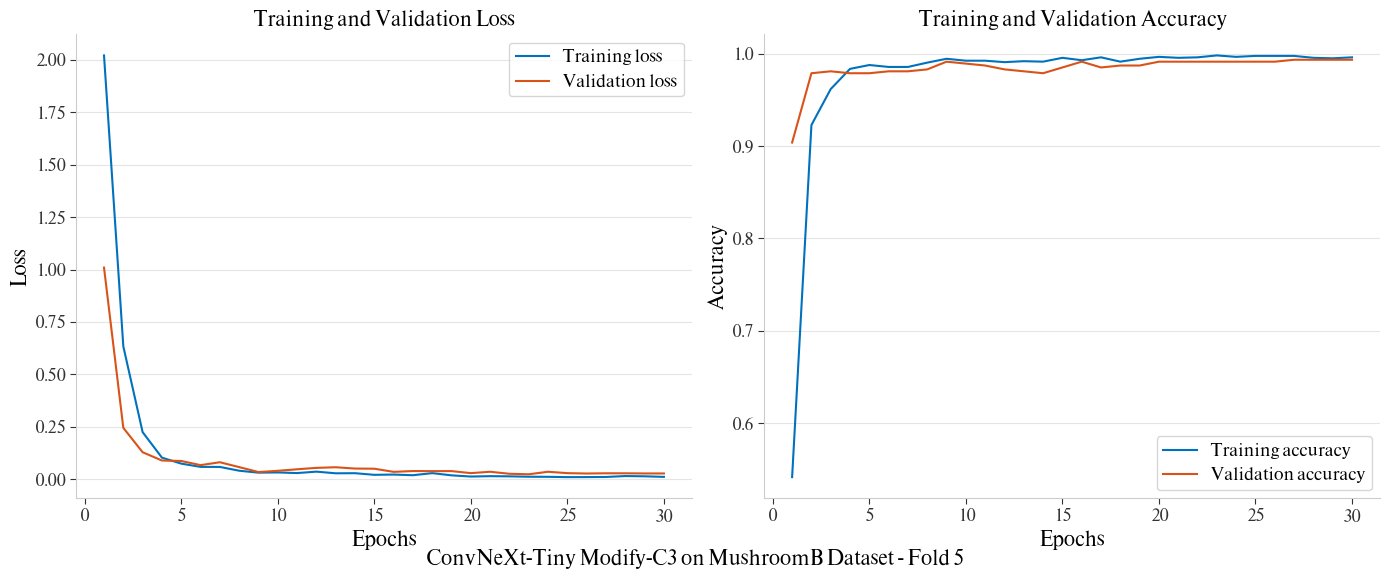

In [ ]:
for fold_key, history in fold_histories.items():
    fold_num = fold_key.split('_')[1]
    fold_dir = f"{trainer.base_dir}/fold_{fold_num}"

    visualization.plot_lr_curve(
        history=history,
        figsize=(14, 6),
        fontsize=14,
        title=f"{sigle_model_title} - Fold {fold_num}",
        save_path=fold_dir
    )

    print('\n')

#### **Overall**

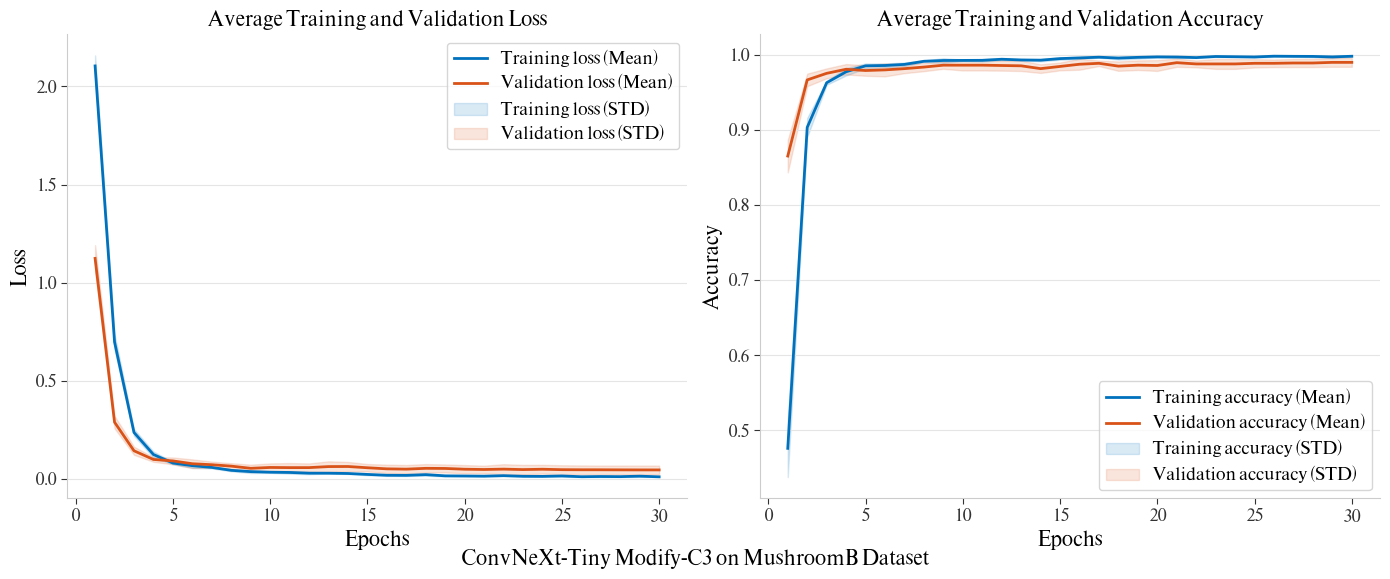

In [ ]:
visualization.plot_cv_summary_curve(
    histories=list(fold_histories.values()),
    figsize=(14, 6),
    fontsize=14,
    title=sigle_model_title,
    save_path=model_ensem_dir
)

### **On validation set**

In [ ]:
individual_validate_perf_df = trainer.evaluate_kfold(
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    dataloader_kwargs=dataloader_kwargs,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type']
)

Evaluating 5-Fold Models on their respective Validation Sets (BEST weights)

[*] Evaluating Fold 1/5 on its Validation Set...
15/15 [==============================] - 3s 210ms/step - loss: 0.0397 - accuracy: 0.9896 - f1: 0.9875 - precision: 0.9875 - recall: 0.9879
[*] Evaluating Fold 2/5 on its Validation Set...
15/15 [==============================] - 4s 257ms/step - loss: 0.0908 - accuracy: 0.9833 - f1: 0.9807 - precision: 0.9808 - recall: 0.9808
[*] Evaluating Fold 3/5 on its Validation Set...
15/15 [==============================] - 4s 292ms/step - loss: 0.0486 - accuracy: 0.9896 - f1: 0.9879 - precision: 0.9892 - recall: 0.9868
[*] Evaluating Fold 4/5 on its Validation Set...
15/15 [==============================] - 4s 237ms/step - loss: 0.0256 - accuracy: 0.9979 - f1: 0.9970 - precision: 0.9970 - recall: 0.9970
[*] Evaluating Fold 5/5 on its Validation Set...
15/15 [==============================] - 4s 280ms/step - loss: 0.0283 - accuracy: 0.9937 - f1: 0.9922 - precision: 0.9921 

### **On test set**

In [ ]:
ensemble_probs, timing_report = trainer.predict_kfold(
    dataloader=test_loader,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type'],
    timer_report_dict=True,
    verbose=1
)

Ensemble Prediction using 5-Fold Models (BEST weights)

[*] Running inference for Fold 1/5...
19/19 [==============================] - 7s 379ms/step

[Inference Report] Latency: 165.62 ms/batch | Throughput: 190.67 samples/sec
    -> Saved fold 1 timing report to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/fold_1/fold_1_infer_timing_report.csv
    -> Saved fold 1 predictions to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/fold_1/fold_1_test_probs_best_weight.csv
[*] Running inference for Fold 2/5...
19/19 [==============================] - 5s 273ms/step

[Inference Report] Latency: 57.81 ms/batch | Throughput: 546.25 samples/sec
    -> Saved fold 2 timing report to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/fold_2/fold_2_infer_timing_report.csv
    -> Saved fold 2 predictions to /content/drive/MyD

In [ ]:
individual_test_perf_df = test.evaluate_preds_kfold(
    base_dir=model_dir,
    n_splits=train.train_config['n_folds'],
    y_true=y_true,
    weight_type=train.train_config['weight_type'],
    task=train.train_config['task'],
    average=train.train_config['average'],
)

[*] Fold 1/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 2/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 3/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 4/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 5/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro

----------------------------------------------------------------------------------------------------
K-Fold Test Set Evaluation Results (Individual Models):
  Fold     loss  accuracy       f1  precision   recall
Fold 1 0.073461  0.983333 0.981861   0.983448 0.981120
Fold 2 0.063369  0.986667 0.984948   0.986103 0.984623
Fold 3 0.076238  0.980000 0.978606   0.980720 0.977507
Fold 4 0.065072  0.985000 0.984104   0.984070 0.984737
Fold 5 0.059603  0.988333 0.988095   0.988972 0.987485
  Mean 0.067549  0.984667 0.983523   0.984662 0.983094
   STD 0.007021  0.003206 0.003543   0.003083 0.003855
---------------------------

## **Section 6: Ensemble model performance**

### **On test set**

In [ ]:
y_pred, metrics = test.evaluate_preds(
    y_true=y_true,
    y_probs=ensemble_probs,
    task=train.train_config['task'],
    average=train.train_config['average'],
    save_path=f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv'
)

[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/ensemble/ensem_test_perf_best_weight.csv


### **Classification report**

In [ ]:
report = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name)

report_dict = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(f'{model_ensem_dir}/ensem_classification_report.csv')

print('Classification Report on Ensemble')
print('=' * 100)
print(report)

Classification Report on Ensemble
                                 precision    recall  f1-score   support

        Amanita_Caesarea-Edible     0.9787    1.0000    0.9892        46
         Amanita_Citrina-Edible     1.0000    0.9429    0.9706        35
   Amanita_Pantherina-NotEdible     0.9851    1.0000    0.9925        66
          Boletus_Regius-Edible     1.0000    1.0000    1.0000        26
       Clitocybe_Costata-Edible     1.0000    0.9259    0.9615        27
     Entoloma_Lividum-NotEdible     0.9615    1.0000    0.9804        25
  Gyromitra_Esculenta-NotEdible     1.0000    0.9778    0.9888        45
         Helvella_Crispa-Edible     1.0000    1.0000    1.0000        62
     Hydnum_Rufescens-NotEdible     1.0000    1.0000    1.0000        31
Hygrophorus_Latitabundus-Edible     1.0000    1.0000    1.0000        26
     Morchella_Deliciosa-Edible     0.9800    1.0000    0.9899        49
  Omphalotus_Olearius-NotEdible     1.0000    1.0000    1.0000        29
    Phallus_Impu

### **Correct predictions**

In [ ]:
df_correct, df_incorrect = test.pred_records(
    y_true=y_true,
    y_pred=y_pred,
    y_probs=ensemble_probs,
    filepaths=[path for path, _ in test_loader.dataset.samples],
    idx_to_class=datasets.idx_to_class,
    save_dir=f'{model_ensem_dir}',
    prefix='ensem'
)

In [ ]:
df_correct

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997705
1,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.998894
2,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997511
3,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.998602
4,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.998734
...,...,...,...,...,...,...
588,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.995853
589,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.996915
590,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.997763
591,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.995244


### **Incorrect predictions**

In [ ]:
df_incorrect

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Amanita_Citrina-Edible...,Russula_Cyanoxantha-Edible,Amanita_Citrina-Edible,14,1,0.868241
1,/content/MushroomB/test/Amanita_Citrina-Edible...,Amanita_Pantherina-NotEdible,Amanita_Citrina-Edible,2,1,0.821380
2,/content/MushroomB/test/Clitocybe_Costata-Edib...,Amanita_Caesarea-Edible,Clitocybe_Costata-Edible,0,4,0.498779
3,/content/MushroomB/test/Clitocybe_Costata-Edib...,Entoloma_Lividum-NotEdible,Clitocybe_Costata-Edible,5,4,0.987208
4,/content/MushroomB/test/Gyromitra_Esculenta-No...,Morchella_Deliciosa-Edible,Gyromitra_Esculenta-NotEdible,10,6,0.996580
5,/content/MushroomB/test/Russula_Cyanoxantha-Ed...,Russula_Delica-NotEdible,Russula_Cyanoxantha-Edible,15,14,0.441252
6,/content/MushroomB/test/Russula_Cyanoxantha-Ed...,Russula_Delica-NotEdible,Russula_Cyanoxantha-Edible,15,14,0.731010


### **Confusion matrix**

#### **without Normalize**

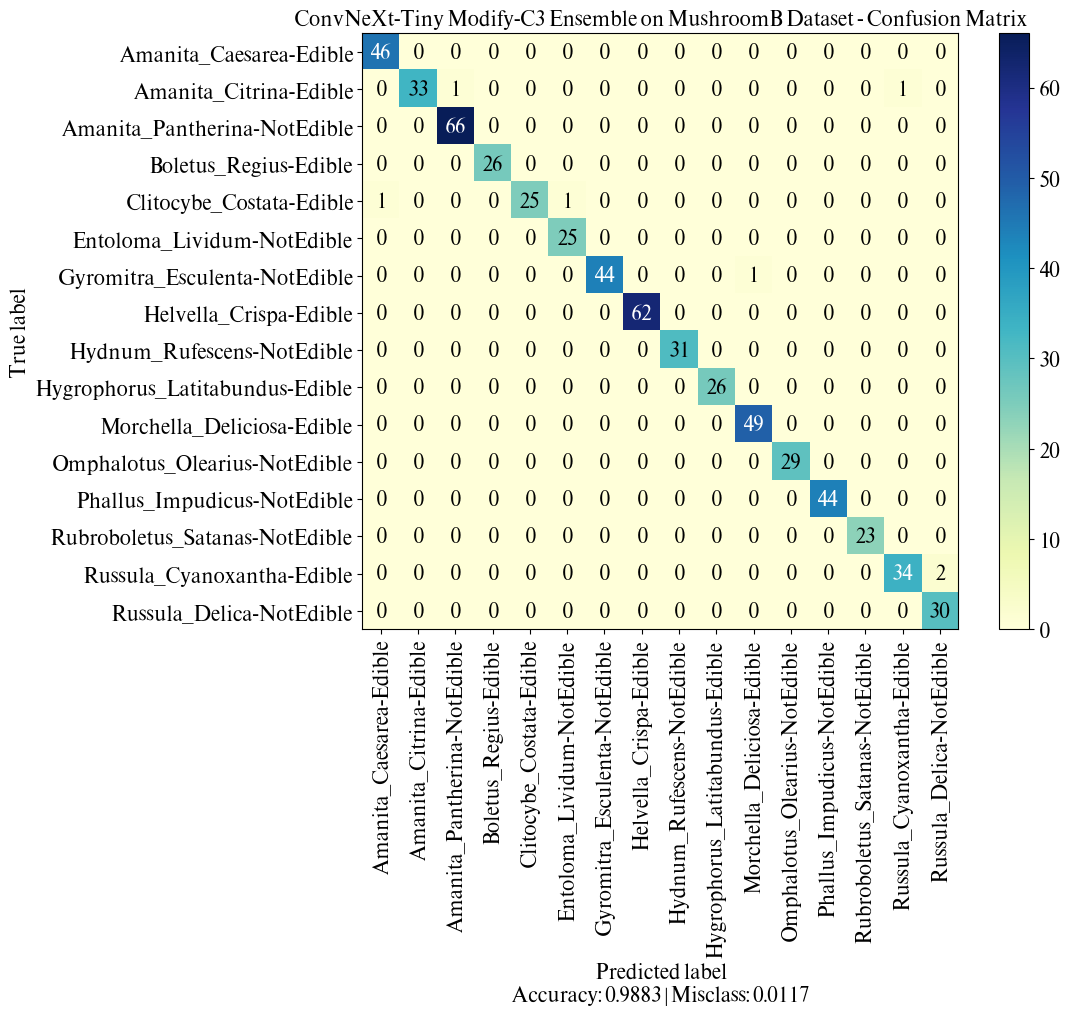

In [ ]:
cm = confusion_matrix(y_true, y_pred)
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=False,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 10),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

#### **with Normalize**

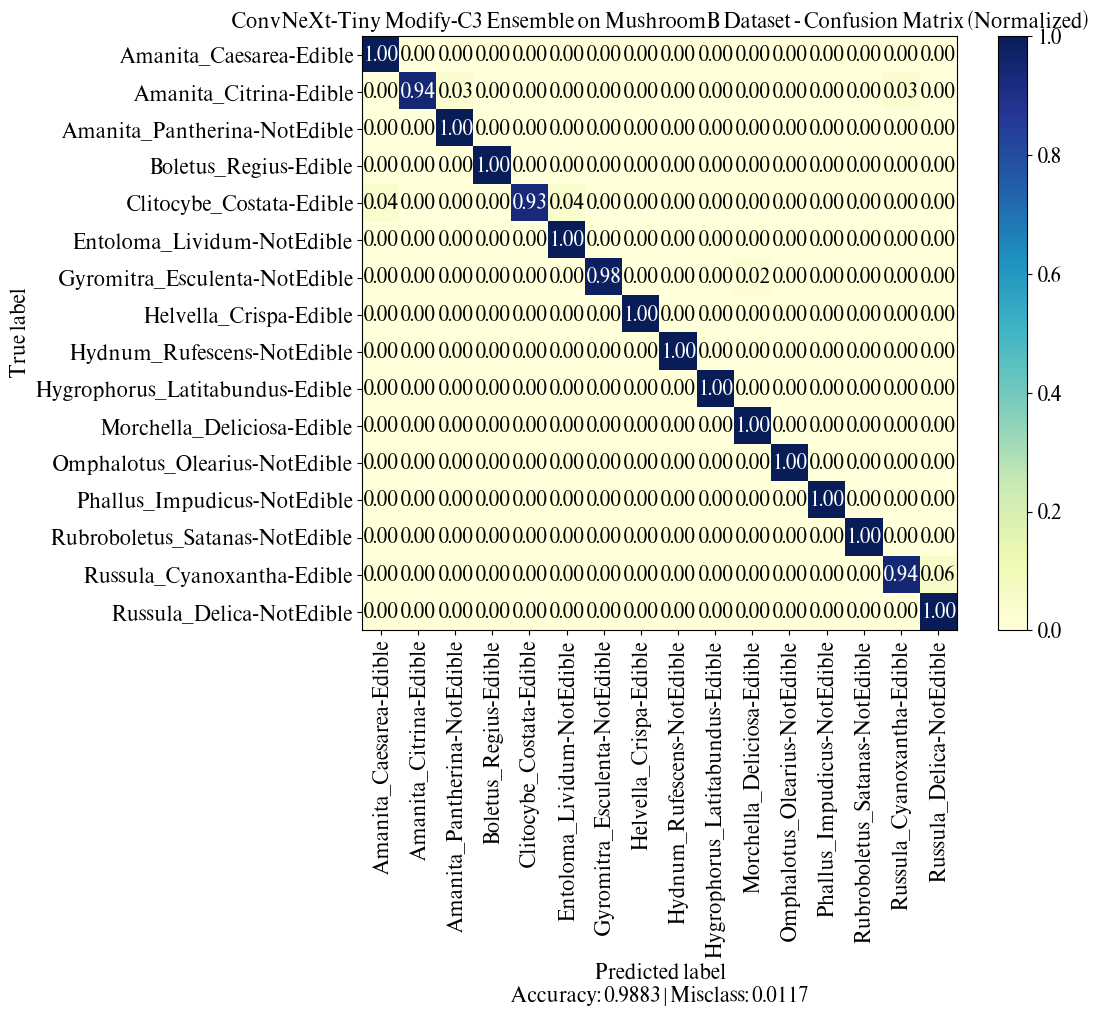

In [ ]:
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=True,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 10),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

### **ROC-AUC curve**

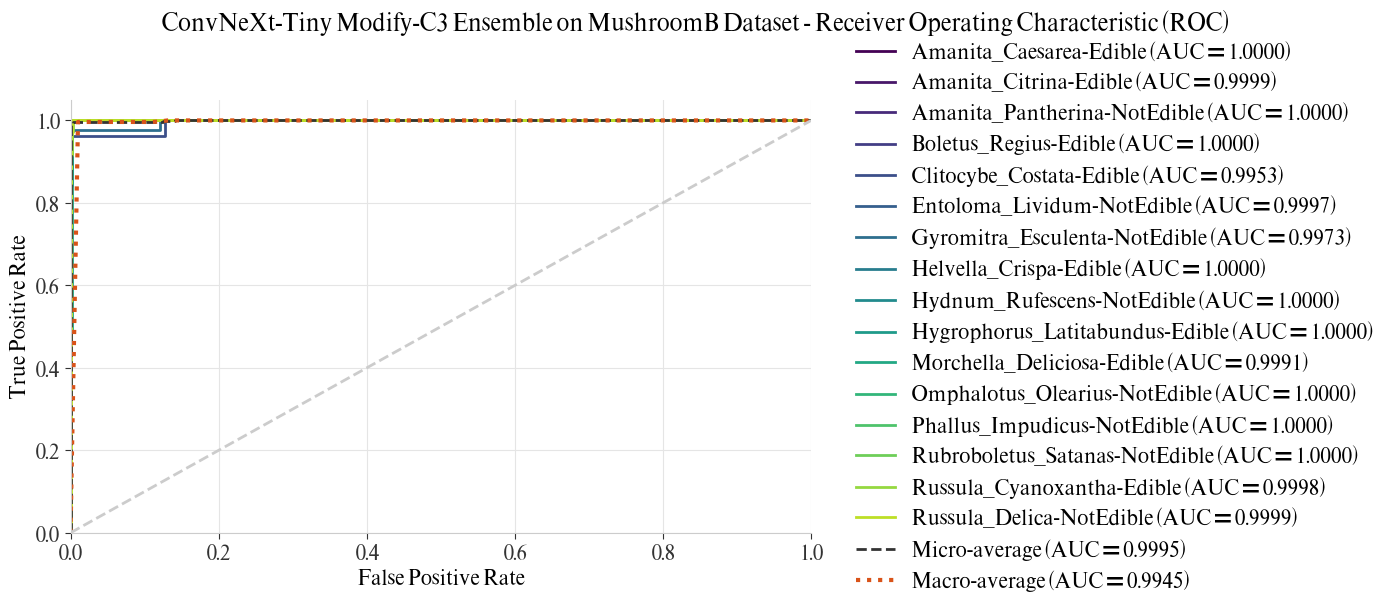

In [ ]:
visualization.plot_roc_auc_curve(
    y_true=y_true,
    y_pred_probs=ensemble_probs,
    class_names=datasets.classes_name,
    task=train.train_config['task'],
    legend_ncol=1,
    figsize=(14, 6),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

## **Section 7: Grad-CAM**

In [ ]:
best_model, best_fold_dir, best_fold_num = trainer.get_best_model_on_validate_set(model_fn=model_fn)
target_layers = [best_model.stages[-1].blocks[-1]]
print(target_layers)

[Logs] Retrieving Best Model from Fold 4
       Primary Metric: accuracy->0.9979 | Secondary: loss->0.0256 on Validation set.
[ConvNeXtBlockModify(
  (conv_dw): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (pre_attn): Identity()
  (mlp): MlpWithMiddleAttention(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU()
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (middle_attn): Identity()
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (post_attn): CoordinateAttention(
    (conv1): Conv2d(768, 48, kernel_size=(1, 1), stride=(1, 1))
    (bn1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act): GELU(approximate='none')
    (conv_h): Conv2d(48, 768, kernel_size=(1, 1), stride=(1, 1))
    (conv_w): Conv2d(48, 768, kernel_size=(1, 1), stri

In [ ]:
unique_label = pd.read_csv(f'{dataset_drive_dir}/unique_label.csv')
#unique_label

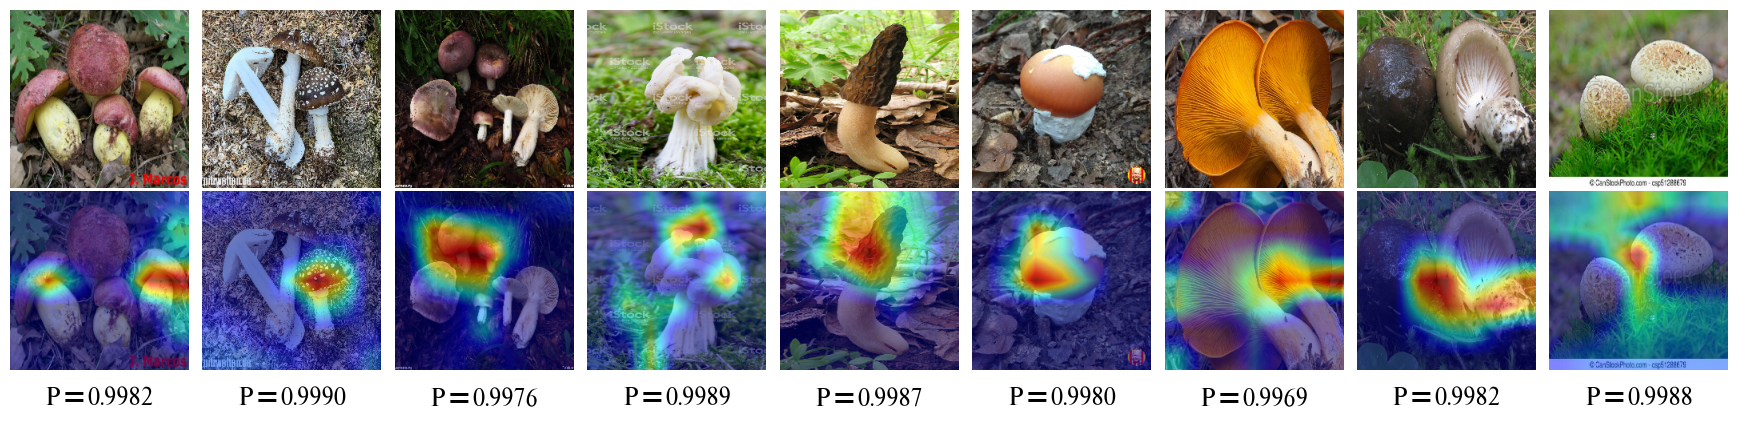

In [ ]:
gradCam.plot_grad_cam(
    model=best_model,
    target_layers=target_layers,
    df=unique_label[:9],
    filepaths_col='Filepaths',
    true_label_col='True_Label',
    true_idx='True_Index',
    device=device,
    transform=transform,
    task=train.train_config['task'],
    reshape_transform=None,
    img_size=model_config['img_size'],
    img_base_size=2,
    row_one_title=False,
    fontsize=16,
    save_path=model_ensem_dir
)

## **Section 8: Summary**

##### **Performace on Validation Set (N Folds)**

In [ ]:
display(individual_validate_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.039704,0.989583,0.987494,0.987495,0.987897
Fold 2,0.090839,0.983333,0.980660,0.980810,0.980829
Fold 3,0.048569,0.989583,0.987865,0.989180,0.986786
Fold 4,0.025612,0.997917,0.996951,0.997024,0.997024
Fold 5,0.028349,0.993737,0.992183,0.992065,0.992845
Mean,0.046615,0.990831,0.989031,0.989315,0.989076
STD,0.026373,0.005431,0.006051,0.005972,0.006165


##### **Performace on Test Set (N Folds)**

In [ ]:
display(individual_test_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.073461,0.983333,0.981861,0.983448,0.981120
Fold 2,0.063369,0.986667,0.984948,0.986103,0.984623
Fold 3,0.076238,0.980000,0.978606,0.980720,0.977507
Fold 4,0.065072,0.985000,0.984104,0.984070,0.984737
Fold 5,0.059603,0.988333,0.988095,0.988972,0.987485
Mean,0.067549,0.984667,0.983523,0.984662,0.983094
STD,0.007021,0.003206,0.003543,0.003083,0.003855


##### **Performace on Test Set (Ensemble)**

In [ ]:
ensem_test_perf_df = pd.read_csv(f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv')
display(ensem_test_perf_df.style.hide(axis="index"))

loss,accuracy,f1,precision,recall
0.056821,0.988333,0.987400,0.988392,0.986938


#### **Model Info**

In [ ]:
flops, macs, params = calflops.calculate_flops(
    model=best_model,
    input_shape=(1,) + model_config['input_size'],
    output_precision=4,
    print_results=False
)

flops_val = float(flops.split()[0])
if 'MFLOPS' in flops:
    flops_val /= 1000.0
flops = f'{flops_val:.4f}'

macs_val = float(macs.split()[0])
if 'MMACs' in macs:
    macs_val /= 1000.0
macs = f'{macs_val:.4f}'

params_val = float(params.split()[0])
if 'K' in params:
    params_val /= 1000.0
elif 'B' in params:
    params_val *= 1000.0
params = f'{params_val:.4f}'

model_summary_report = {
    'Batch Size': [train.train_config['batch_size']],
    'Image Size': [f'{img_size[0]}\u00D7{img_size[1]}'],
    'GFLOPs': [flops],
    'GMACs': [macs],
    'Params (M)': [params],
    'Latency (ms/img)': timing_report['avg_single_model_latency_sample'],
    'Latency (ms/batch)': timing_report['avg_single_model_latency_batch'],
    'Throughput (img/s)': timing_report['avg_single_model_throughput'],
}

model_summary_df = pd.DataFrame(model_summary_report)
model_summary_df.to_csv(f'{model_summary_dir}/model_summary.csv', index=False)
display(model_summary_df.style.hide(axis="index"))

Batch Size,Image Size,GFLOPs,GMACs,Params (M),Latency (ms/img),Latency (ms/batch),Throughput (img/s)
32,224×224,8.9462,4.4589,28.0432,1.838495,58.057726,543.927847


## **Section 9: Addition**

##### **Preparation**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

add_drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
add_dataset_name = 'MushroomB'

def get_model_dir(model_name_path, weights_root='modelWeights', dataset_name=add_dataset_name):
    return os.path.join(add_drive_dir, f'{weights_root}/{dataset_name}', f'{model_name_path}_{dataset_name}')

# Model of this notebook
add_weights_root = 'myModelWeights'
modify_type = 'C3' # เปลี่ยนเสมอ
add_model_name_path = f'convnext_tiny_modify_{modify_type}_224_r1_v1'
add_model_name = f'ConvNeXt-Tiny Modify-{modify_type}'
add_model_dir = get_model_dir(add_model_name_path, weights_root=add_weights_root)

# McNemar's test: Baseline vs Proposed (Default proposed = model of this notebook)
mc_baseline_name = 'ConvNeXt-Tiny'
mc_baseline_model_dir = get_model_dir('convnext_tiny_224_r1_v1', weights_root='modelWeights')
mc_proposed_name = add_model_name
mc_proposed_model_dir = add_model_dir
mc_alpha = 0.05

add_config = {
    'n_folds': 5,
    'task': 'multiclass',
    'average': 'macro',
    'weight_type': 'best',
}

add_plot_kwargs = {
    'cmap': plt.cm.YlGnBu,
    'fontsize': 14,
}

In [3]:
os.chdir(add_drive_dir)
print(f'Current directory: {os.getcwd()}')
print(f'Model directory   : {add_model_dir}')
print(f'Baseline directory: {mc_baseline_model_dir}')
print(f'Proposed directory: {mc_proposed_model_dir}')

import src.visualization as visualization
import src.ensembleVoting as ensembleVoting
import src.mcnemarTest as mcnemarTest

visualization.matplotlib_font(font_dir=f'{add_drive_dir}/assets/fonts', prefer_name='Times-Roman')

Current directory: /content/drive/MyDrive/projectMushroom
Model directory   : /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB
Baseline directory: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v1_MushroomB
Proposed directory: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB


'OPTITimes-Roman'

##### **Compare voting strategies on test set**

[*] Loaded Fold 1/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 2/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 3/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 4/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 5/5 probabilities | Shape: (600, 16)
[*] Recovered test order verified against /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/ensemble/ensem_test_probs_best_weight.csv
[*] Recovered 600 test samples | 16 classes
[Logs] Saved Voting Weights to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/ensemble_addition/voting_weights_best_weight.csv

Voting Method: SOFT
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/ensemble_addition/soft/soft_test_perf_best_weight.csv
                                 precision    recall  f1-sc

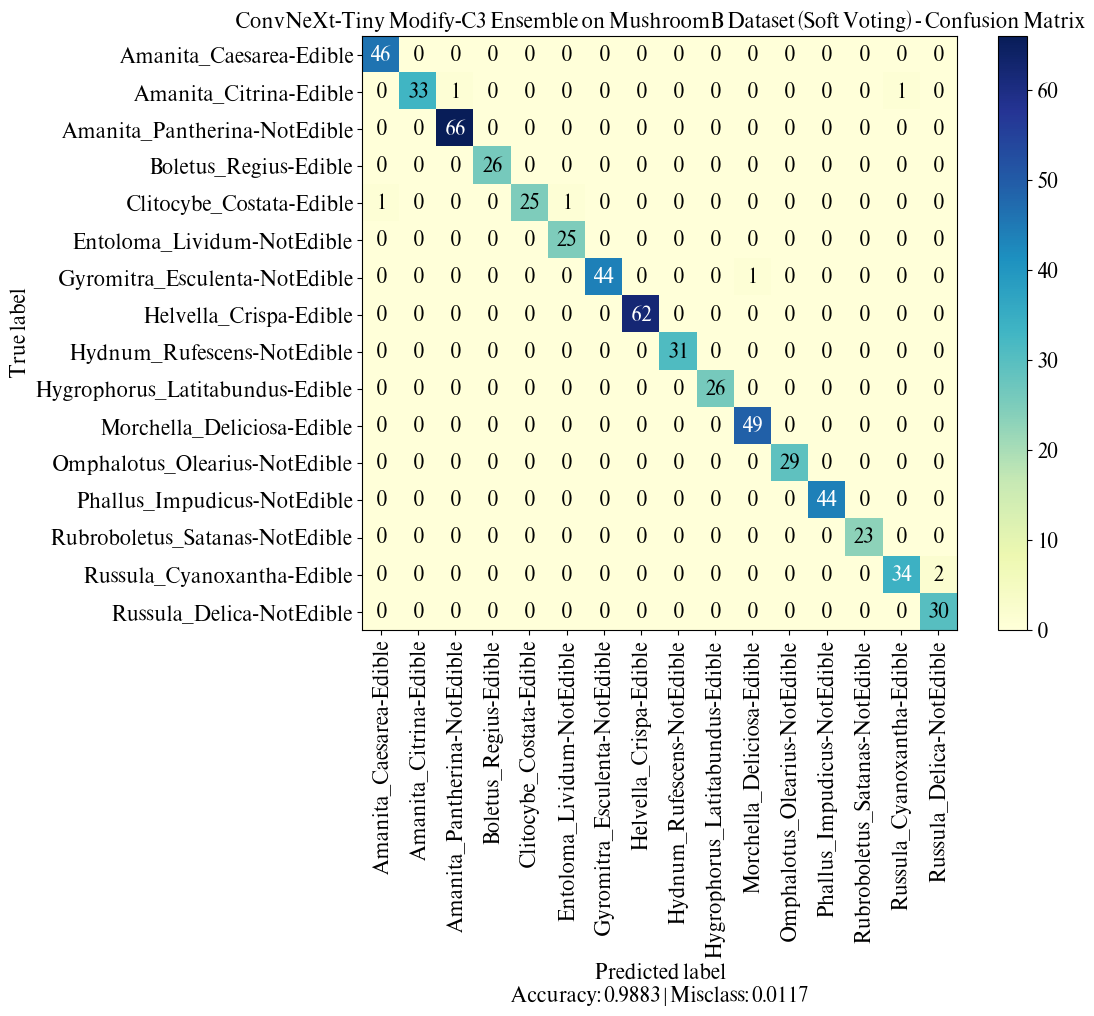

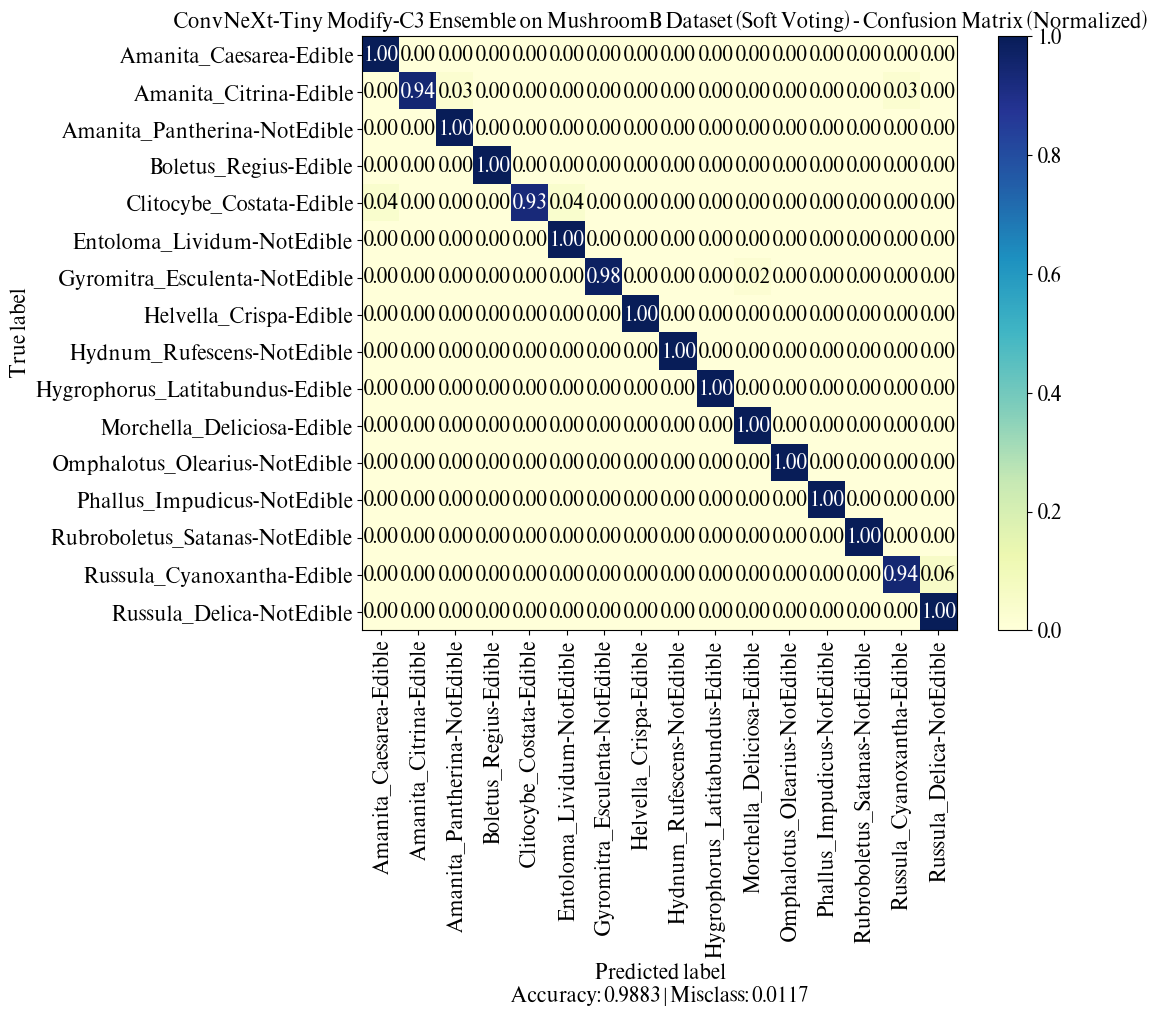

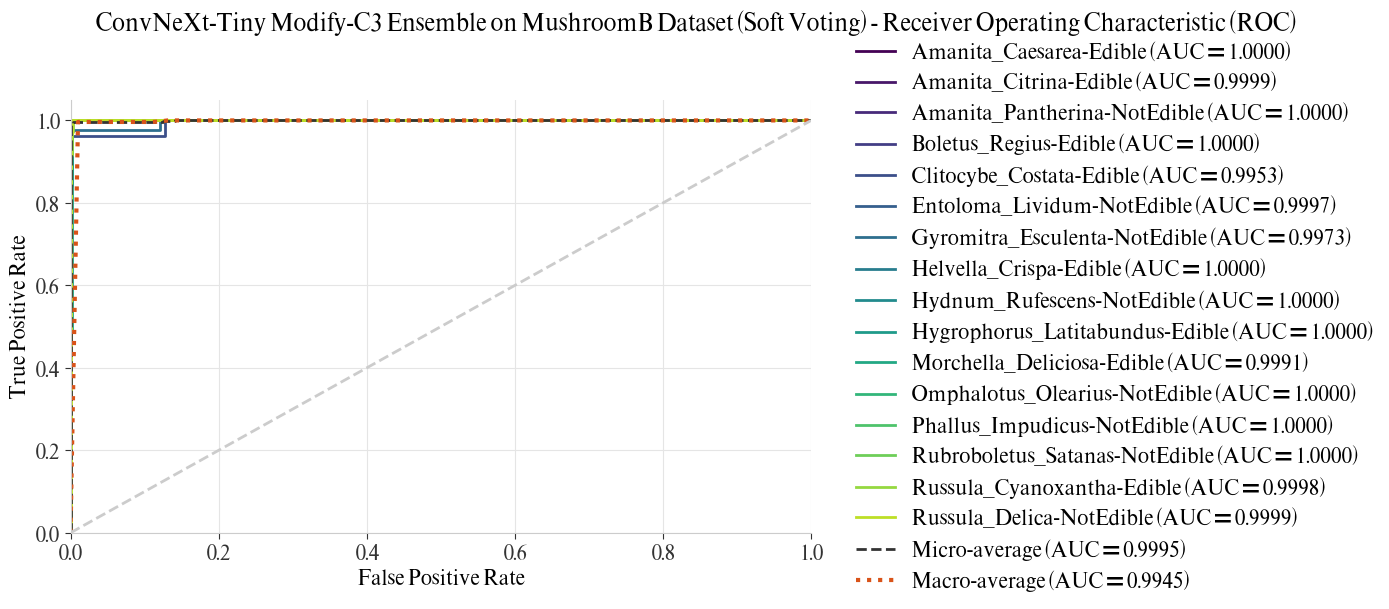




Voting Method: HARD
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/ensemble_addition/hard/hard_test_perf_best_weight.csv
                                 precision    recall  f1-score   support

        Amanita_Caesarea-Edible     0.9787    1.0000    0.9892        46
         Amanita_Citrina-Edible     1.0000    0.9429    0.9706        35
   Amanita_Pantherina-NotEdible     0.9851    1.0000    0.9925        66
          Boletus_Regius-Edible     1.0000    1.0000    1.0000        26
       Clitocybe_Costata-Edible     1.0000    0.9259    0.9615        27
     Entoloma_Lividum-NotEdible     0.9259    1.0000    0.9615        25
  Gyromitra_Esculenta-NotEdible     1.0000    0.9778    0.9888        45
         Helvella_Crispa-Edible     1.0000    1.0000    1.0000        62
     Hydnum_Rufescens-NotEdible     1.0000    1.0000    1.0000        31
Hygrophorus_Latitabundus-Edible     1.0000    1.0000    1.0

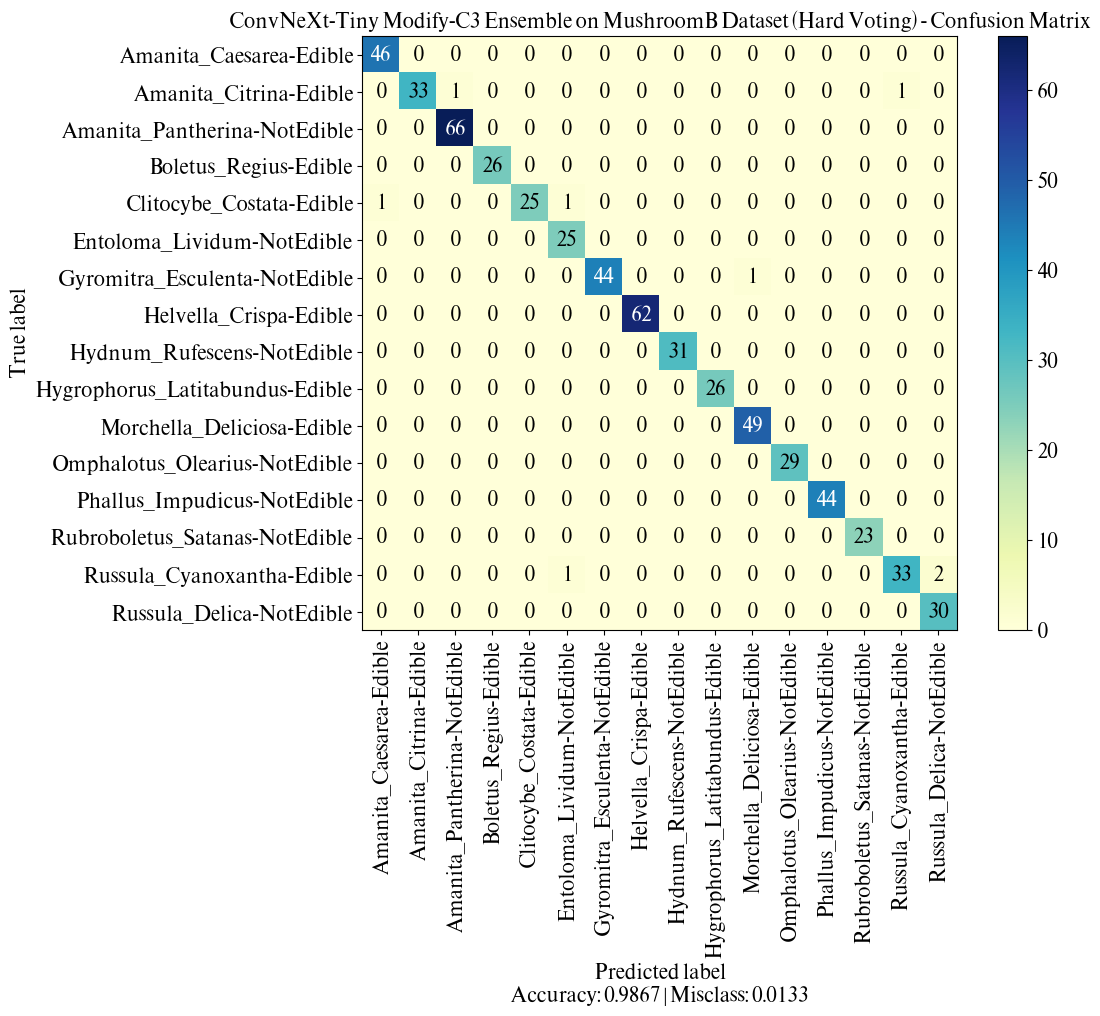

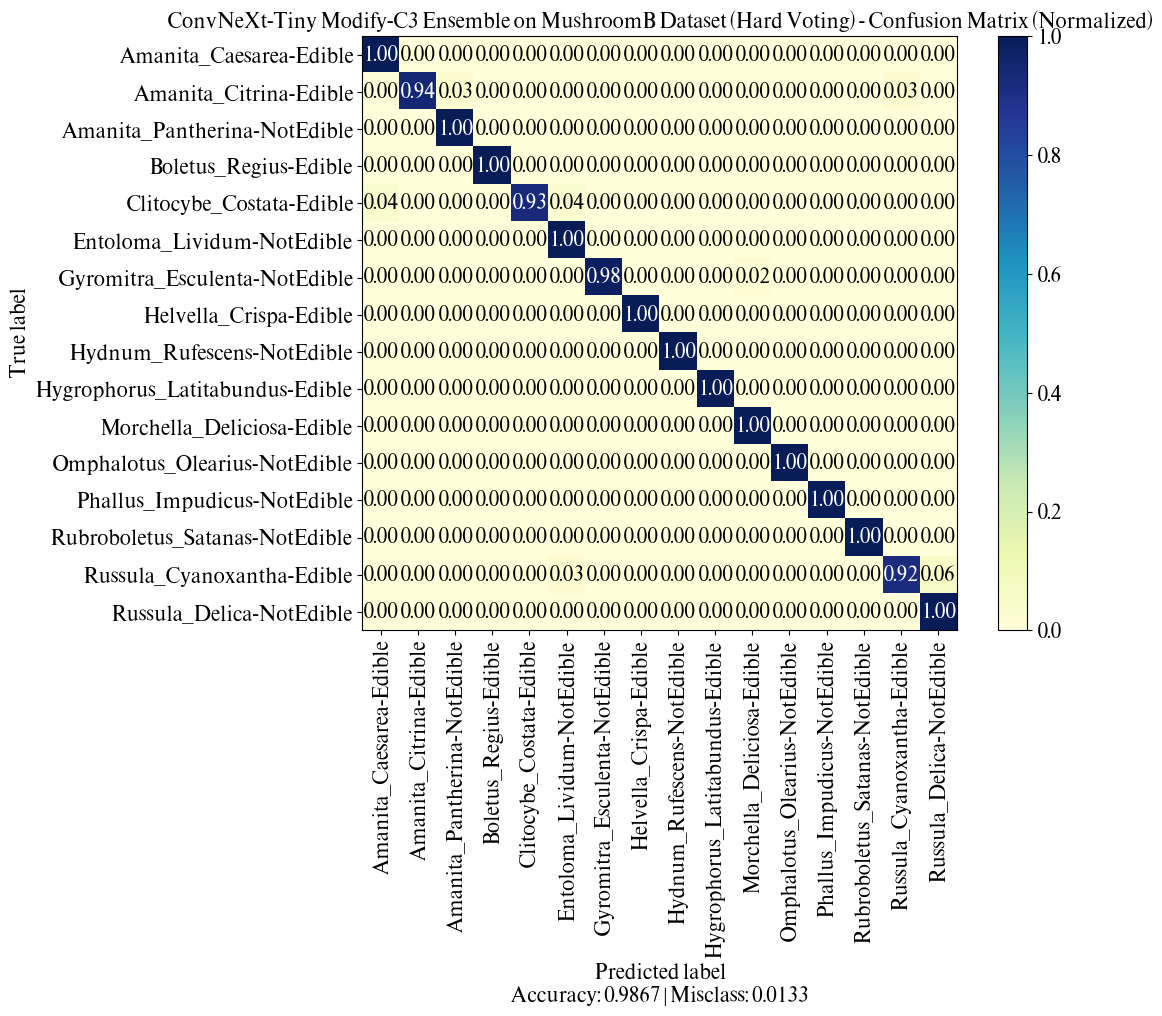




Voting Method: WEIGHTED
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/ensemble_addition/weighted/weighted_test_perf_best_weight.csv
                                 precision    recall  f1-score   support

        Amanita_Caesarea-Edible     0.9787    1.0000    0.9892        46
         Amanita_Citrina-Edible     1.0000    0.9429    0.9706        35
   Amanita_Pantherina-NotEdible     0.9851    1.0000    0.9925        66
          Boletus_Regius-Edible     1.0000    1.0000    1.0000        26
       Clitocybe_Costata-Edible     1.0000    0.9259    0.9615        27
     Entoloma_Lividum-NotEdible     0.9615    1.0000    0.9804        25
  Gyromitra_Esculenta-NotEdible     1.0000    0.9778    0.9888        45
         Helvella_Crispa-Edible     1.0000    1.0000    1.0000        62
     Hydnum_Rufescens-NotEdible     1.0000    1.0000    1.0000        31
Hygr

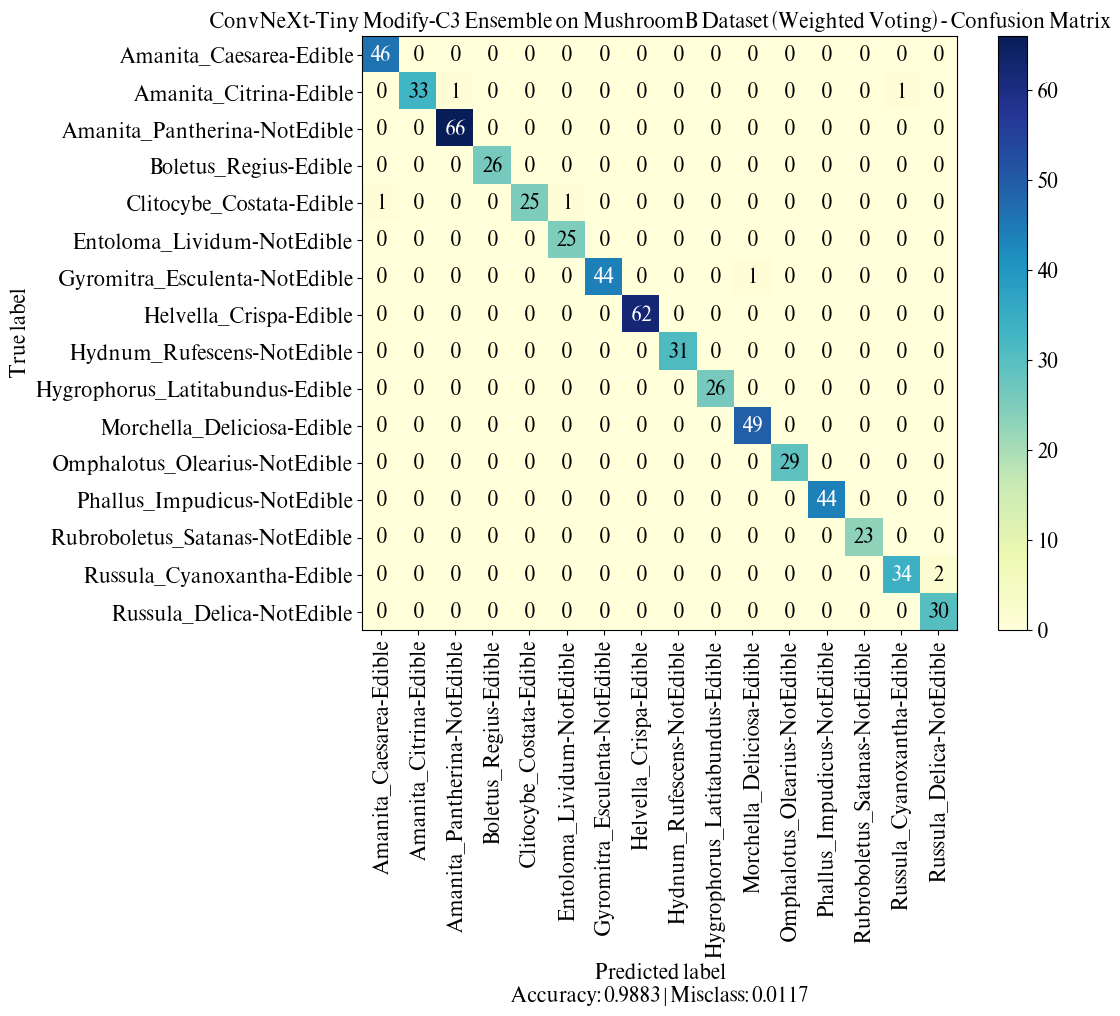

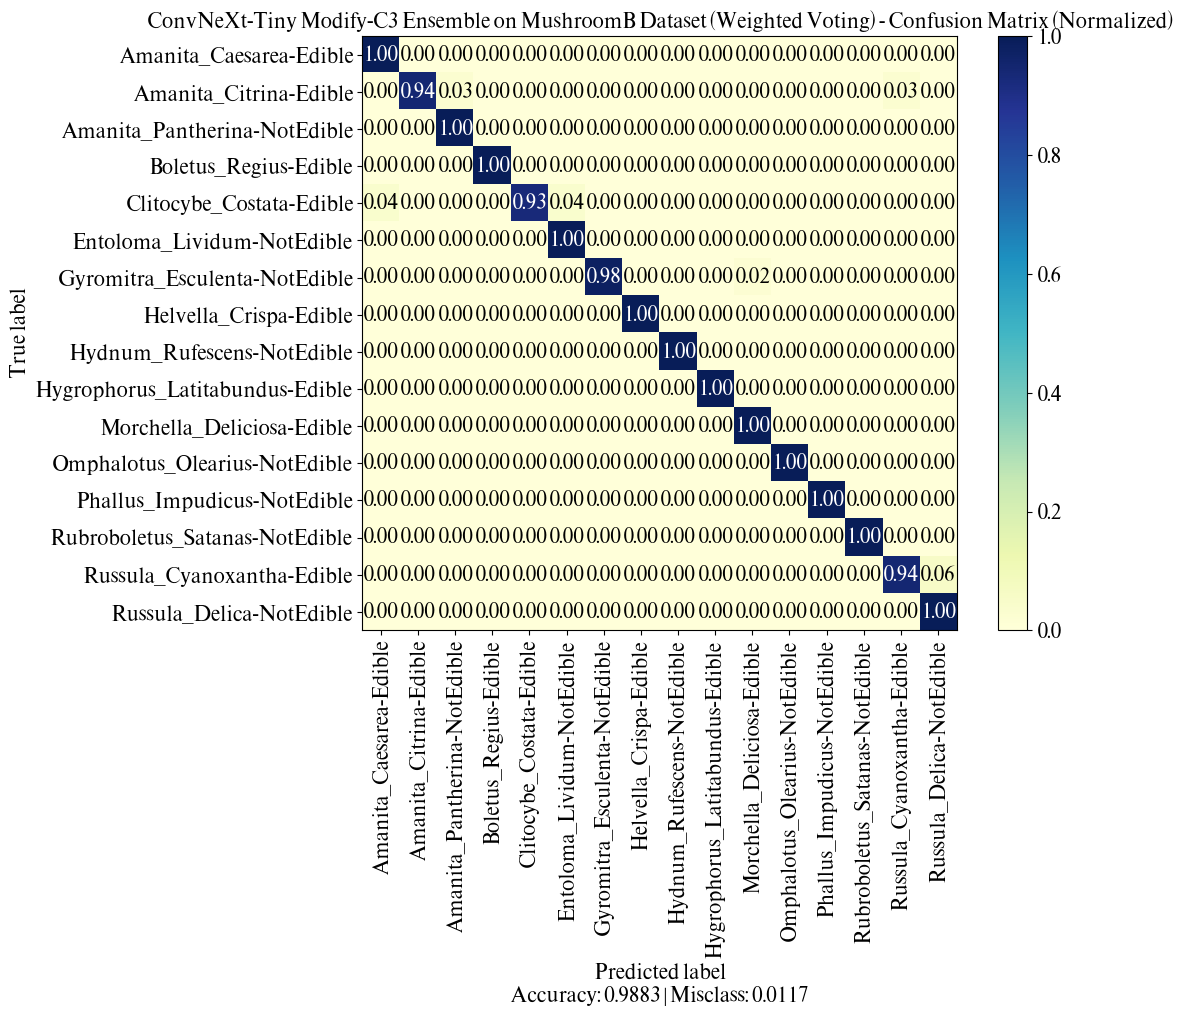

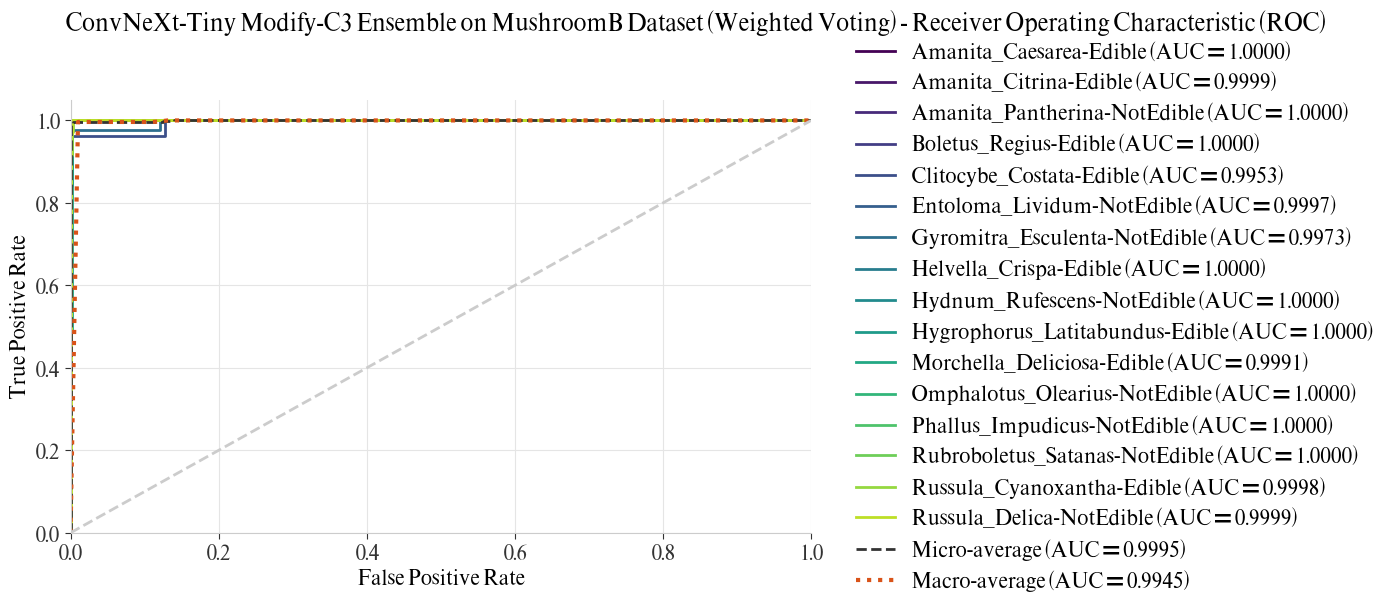




----------------------------------------------------------------------------------------------------
Ensemble Voting Comparison on Test Set (5 models):
         Method     loss  accuracy       f1  precision   recall  n_models  Aggregation Latency (ms/img)  Inference Latency (ms/img)  Total Latency (ms/img)
    Soft Voting 0.056821  0.988333 0.987400   0.988392 0.986938         5                      0.000140                    9.192473                9.192613
    Hard Voting      NaN  0.986667 0.985291   0.986113 0.985202         5                      0.000715                    9.192473                9.193188
Weighted Voting 0.056813  0.988333 0.987400   0.988392 0.986938         5                      0.000182                    9.192473                9.192655
----------------------------------------------------------------------------------------------------
[Logs] Saved Voting Comparison to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_

In [4]:
voting_comparison_df, voting_results = ensembleVoting.compare_voting_strategies(
    base_dir=add_model_dir,
    n_splits=add_config['n_folds'],
    weight_type=add_config['weight_type'],
    task=add_config['task'],
    average=add_config['average'],
    title=f'{add_model_name} Ensemble on {add_dataset_name} Dataset',
    cm_figsize=(12, 10),
    roc_figsize=(14, 6),
    **add_plot_kwargs,
)

##### **Voting weights (from validation accuracy)**

In [5]:
voting_weights_df = pd.read_csv(f"{add_model_dir}/ensemble_addition/voting_weights_{add_config['weight_type']}_weight.csv")
display(voting_weights_df.style.hide(axis="index"))

Fold,val_accuracy,weight
Fold 1,0.989583,0.199748
Fold 2,0.983333,0.198487
Fold 3,0.989583,0.199748
Fold 4,0.997917,0.201430
Fold 5,0.993737,0.200587


##### **Performance on Test Set (Voting comparison, latency in ms/img)**

In [6]:
display(voting_comparison_df.style.hide(axis="index"))

Method,loss,accuracy,f1,precision,recall,n_models,Aggregation Latency (ms/img),Inference Latency (ms/img),Total Latency (ms/img)
Soft Voting,0.056821,0.988333,0.987400,0.988392,0.986938,5,0.000140,9.192473,9.192613
Hard Voting,nan,0.986667,0.985291,0.986113,0.985202,5,0.000715,9.192473,9.193188
Weighted Voting,0.056813,0.988333,0.987400,0.988392,0.986938,5,0.000182,9.192473,9.192655


##### **McNemar's test (Baseline vs Proposed)**

ConvNeXt-T vs Modify

[*] Loaded 600 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v1_MushroomB/ensemble
[*] Loaded 600 predictions from /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_C3_224_r1_v1_MushroomB/ensemble
[*] Aligned 600 test samples (Filepaths and true labels verified)

----------------------------------------------------------------------------------------------------
McNemar's Test: ConvNeXt-Tiny Modify-C3 vs ConvNeXt-Tiny (N = 600)
                                   ConvNeXt-Tiny Correct  ConvNeXt-Tiny Incorrect
ConvNeXt-Tiny Modify-C3 Correct                      592                        1
ConvNeXt-Tiny Modify-C3 Incorrect                      2                        5

Chi-square = 0.0000 | p-value = 1 | Exact p-value = 1
alpha = 0.05 -> Fail to reject H0 (no significant difference)
----------------------------------------------------------------------------------------------------
[Logs] Saved Mc

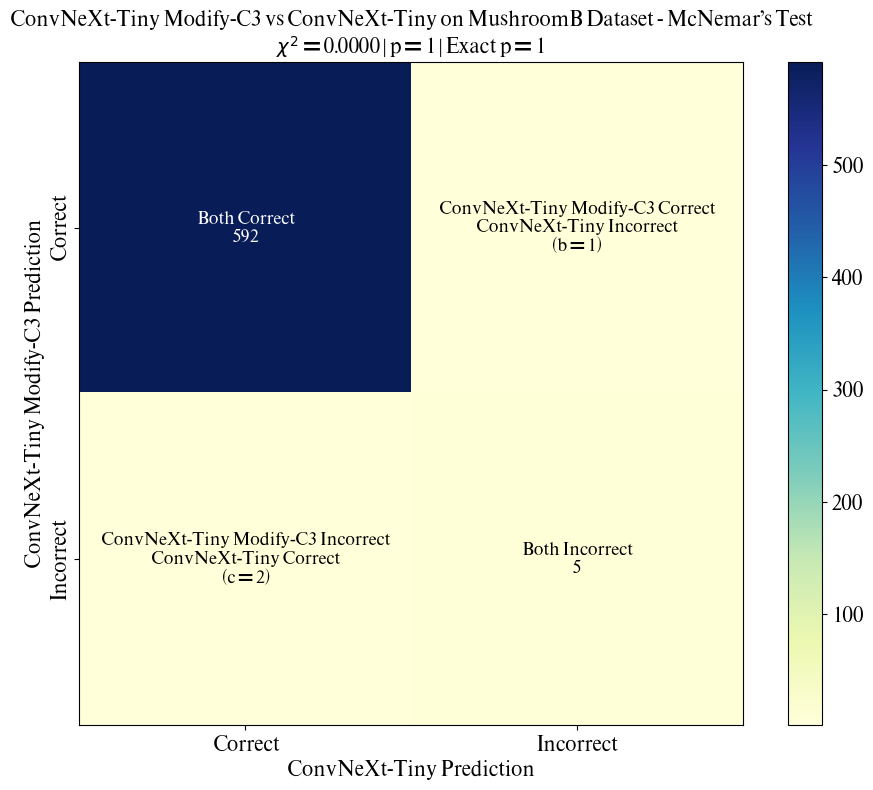

In [7]:
mcnemar_result_df, mcnemar_aligned_df = mcnemarTest.compare_mcnemar(
    baseline_model_dir=mc_baseline_model_dir,
    proposed_model_dir=mc_proposed_model_dir,
    baseline_name=mc_baseline_name,
    proposed_name=mc_proposed_name,
    alpha=mc_alpha,
    title=f'{mc_proposed_name} vs {mc_baseline_name} on {add_dataset_name} Dataset',
    figsize=(10, 8),
    **add_plot_kwargs,
)

##### **McNemar's test result**

In [8]:
display(mcnemar_result_df.style.hide(axis="index"))

Baseline,Proposed,N,Baseline Accuracy,Proposed Accuracy,Accuracy Diff (pp),Both Correct,"b (Proposed Correct, Baseline Incorrect)","c (Proposed Incorrect, Baseline Correct)",Both Incorrect,Chi-square,p-value,Exact p-value,Alpha,Significant
ConvNeXt-Tiny,ConvNeXt-Tiny Modify-C3,600,0.990000,0.988333,-0.166667,592,1,2,5,0.000000,1.000000,1.000000,0.050000,False


##### **Disagreement samples (Only one model is correct)**

In [9]:
mcnemar_aligned_df[mcnemar_aligned_df['Baseline_Correct'] != mcnemar_aligned_df['Proposed_Correct']]

,Filepaths,True_Index,True_Label,Baseline_Pred_Index,Baseline_Pred_Label,Proposed_Pred_Index,Proposed_Pred_Label,Baseline_Correct,Proposed_Correct
50,/content/MushroomB/test/Amanita_Citrina-Edible...,1,Amanita_Citrina-Edible,1,Amanita_Citrina-Edible,14,Russula_Cyanoxantha-Edible,True,False
348,/content/MushroomB/test/Hydnum_Rufescens-NotEd...,8,Hydnum_Rufescens-NotEdible,0,Amanita_Caesarea-Edible,8,Hydnum_Rufescens-NotEdible,False,True
543,/content/MushroomB/test/Russula_Cyanoxantha-Ed...,14,Russula_Cyanoxantha-Edible,14,Russula_Cyanoxantha-Edible,15,Russula_Delica-NotEdible,True,False
